In [1]:
import agama, numpy
from astropy import units as u 
from astropy import constants as cnst
import pathlib
import pyfalcon
import configparser

In [2]:
def rotate(posvel, angle):
    x, y, z, vx, vy, vz = posvel.T
    sina, cosa = numpy.sin(angle), numpy.cos(angle)
    return numpy.array([x*cosa-y*sina, x*sina+y*cosa, z, vx*cosa-vy*sina, vx*sina+vy*cosa, vz]).T

def load_potential_parameters(*ini_paths):
	parameters = {}
	for ini_path in ini_paths:
		config = configparser.ConfigParser()
		config.optionxform = str
		config.read(ini_path)
		for section in config.sections():
			if not section.startswith("Potential "):
				continue
			name = section.removeprefix("Potential ")
			parameters[name] = {
				key: value if key == "type" else float(value)
				for key, value in config[section].items()
			}
	return parameters

def rescale_ini_dict(parameters, unitM, unitL, unitM_OG=u.Msun, unitL_OG=u.kpc):
    """
    Expects the ini files to have been parsed with load_potential_parameters
    """
    parameters_rescaled = {}
    for key,value in parameters.items():
        parameters_rescaled[key] = {}
        for key_,value_ in value.items():
            if key_.startswith("mass"):
                parameters_rescaled[key][key_] = (value_*unitM_OG).to(unitM).value
            elif key_.startswith("scale"):
                parameters_rescaled[key][key_] = (value_*unitL_OG).to(unitL).value
            else:
                parameters_rescaled[key][key_] = value_    
    return parameters_rescaled

In [3]:
path_bar = "/Users/ferrone/repos/bar-dynamics/parameters/components/bar_ferrers_v1.ini"
path_ext = "/Users/ferrone/repos/bar-dynamics/parameters/components/mw_fiducial_v1.ini"
parameters_ext = load_potential_parameters(path_ext)
parameters_bar = load_potential_parameters(path_bar)
barconfig = configparser.ConfigParser()
barconfig.read(path_bar)

['/Users/ferrone/repos/bar-dynamics/parameters/components/bar_ferrers_v1.ini']

set the units 

In [4]:
oldUnitG    =   (u.km/u.s)**2 * (u.kpc/u.Msun)
G           =   cnst.G.to(oldUnitG)
unitM   =   parameters_bar["bar"]["mass"]*u.Msun
unitL   =   parameters_bar["bar"]["scaleRadius"]*u.kpc
unitV   =   (G*unitM/unitL)**(1/2)
unitRot =   unitV/unitL
agama.setUnits(length=unitL.value, mass=unitM.value, velocity=unitV.value) 

rescale the parameters

In [5]:
parameters_ext_rescaled = rescale_ini_dict(parameters_ext,unitM=unitM,unitL=unitL)
parameters_bar_rescaled = rescale_ini_dict(parameters_bar,unitM=unitM,unitL=unitL)
omega = numpy.float64(barconfig["orientation"]["pattern_speed_kms_kpc"]) * (u.km/u.s)/u.kpc
omega = omega.to(unitRot).value

create the model in agama

In [6]:
thin_disk   = agama.Potential(**parameters_ext_rescaled['thin_disk'])
thick_disk  = agama.Potential(**parameters_ext_rescaled['thick_disk'])
halo        = agama.Potential(**parameters_ext_rescaled['halo'])
bar         = agama.Potential(**parameters_bar_rescaled["bar"])
potential_external = thin_disk + thick_disk + halo
potential_total = bar + potential_external

load the orbit

In [7]:
snap_mass = numpy.load("ferrers_bar_nbody_100_mass.npy")
snap_posvel = numpy.load("ferrers_bar_nbody_100_phase_space.npy")
nbody = snap_mass.shape[0]

In [8]:
barvolume=numpy.pi*parameters_bar_rescaled["bar"]['scaleRadius']**3 * parameters_bar_rescaled["bar"]['axisRatioY'] * parameters_bar_rescaled["bar"]["axisRatioZ"]
meandensity = bar.totalMass() / barvolume
interparticledistance = (barvolume / nbody)**(1/3)
interparticledistance

np.float64(0.14008317458759553)

In [9]:
treeAngle = 0.1 # 0 means exact n body summation 

In [10]:
# 1 pc
eps = 1e-3 * u.kpc
eps = eps.to(unitL).value # softening length
eps = interparticledistance / 1e1

In [11]:
# the time step is related to the size of the small guy 
dt = (1/50)*numpy.sqrt(eps**3 / snap_mass.mean() )
integrationtime = (1/1)*u.Gyr
unitT = unitL/unitV
integrationtime= integrationtime.to(unitT).value
nsteps = int(integrationtime // dt)
integrationtime = dt * nsteps
print("integration time", (integrationtime*unitT).to(u.Myr))
print("integration time", (dt*unitT).to(u.Myr))

integration time 999.9908997270061 Myr
integration time 0.010237102666042263 Myr


In [12]:
nbody = snap_mass.shape[0]
nphase = 6 
# get the data volume 
print(nsteps,nbody,nphase)
print((nbody*nphase*nsteps*64*u.bit).to(u.Gbyte))

97683 100 6
0.46887840000000003 Gbyte


In [13]:
# initialize! 
potential_int = numpy.zeros((nsteps+1,nbody))
potential_ext = numpy.zeros((nsteps+1,nbody))

trajectory = numpy.zeros((nsteps+1,nbody,nphase))
vel = snap_posvel[:,3:6].copy()
pos = snap_posvel[:,0:3].copy()
i =0
trajectory[0,:,:] = snap_posvel.copy()
f_int,pot_int=pyfalcon.gravity(pos, snap_mass, eps=eps, theta=treeAngle)
pot_ext, f_ext = potential_external.eval(pos,pot=True, acc=True)
potential_int[i] = pot_int
potential_ext[i] = pot_ext

In [14]:
for i in range(1,nsteps+1):
    # drift based on a half step 
    pos += 0.5 * dt * vel
    # now update the forces
    f_int,pot_int=pyfalcon.gravity(pos, snap_mass, eps=eps, theta=treeAngle)
    pot_ext, f_ext = potential_external.eval(pos,pot=True, acc=True)
    force = f_int+f_ext
    vel += dt * force
    # another half step 
    pos += 0.5 * dt * vel
    trajectory[i,:,0:3] = pos
    trajectory[i,:,3:6] = vel
    # I should update the potential to the new position, but check first
    f_int,pot_int=pyfalcon.gravity(pos, snap_mass, eps=eps, theta=treeAngle)
    pot_ext, f_ext = potential_external.eval(pos,pot=True, acc=True)    
    potential_int[i] = pot_int
    potential_ext[i] = pot_ext

In [15]:
kinetic=(1/2)*snap_mass*numpy.sum(trajectory[:,:,3:6]**2,axis=2)
potential_energy = (1/2)*snap_mass*potential_int + snap_mass*potential_ext
# don't forget the 1/2 because we multiple the terms twice 
E_total = potential_energy + kinetic
total_energy = numpy.sum(E_total,axis=1)
timesteps = numpy.linspace(0,integrationtime,nsteps+1)
eDrift = numpy.abs((total_energy - total_energy[0]) / total_energy[0])

show the bar frame

In [16]:
traj_barframe = numpy.zeros_like(trajectory)
for i in range(nsteps+1):
    traj_barframe[i,:,:] = rotate(trajectory[i,:,:],angle=omega*timesteps[i])

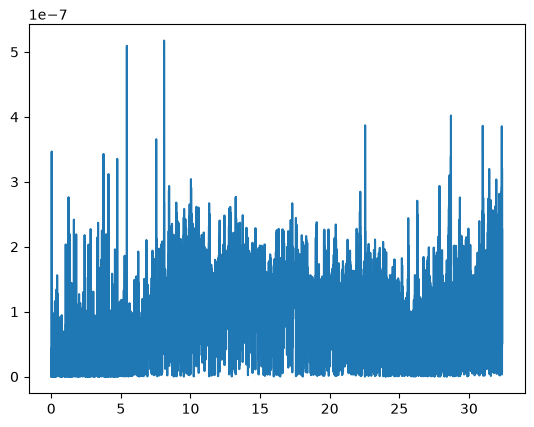

In [17]:
from matplotlib import pyplot as plt 
fig,axis=plt.subplots(1,1)
axis.plot(timesteps,eDrift)

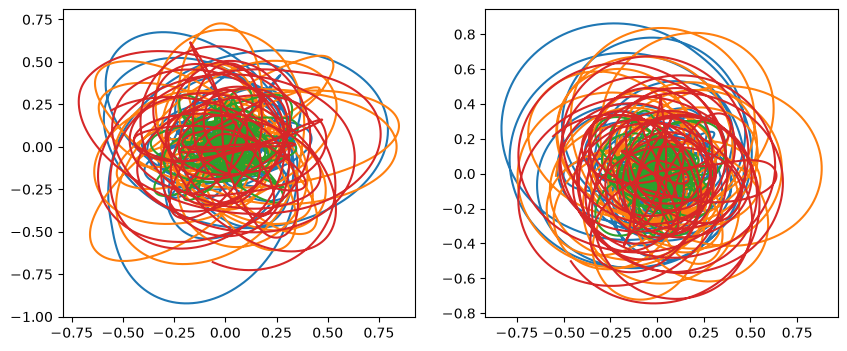

In [35]:
fig,axis=plt.subplots(1,2,figsize=(10,4))
orbit_index = 10
aa = 10
bb= 4
for orbit_index in range(aa,aa+bb):
    axis[0].plot(trajectory[:,orbit_index,0],trajectory[:,orbit_index,1]);
    axis[1].plot(traj_barframe[:,orbit_index,0,],traj_barframe[:,orbit_index,1]);